# H4 statistical checks: normality and equal variances

**Premises (settled so far)**
- Stable window: WEEK_NO 17 to 99
- Early window (N): 10 weeks (from the start of the stable window); 8-week/12-week sensitivity checks come later, by changing only the EARLY_N value
- Top X%: 20% (the Lorenz curve and kneed results both agree near 20%)
- Outliers are not removed separately (judged to be within the normal range for this domain, defended by nonparametric tests)

Before testing the two comparisons of H4-1 (1. paired change in absolute amount, 2. independent comparison of the increase, top X% vs the rest),
this notebook **first checks normality and equal variances**, and uses the results to settle the tests to use afterwards.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

candidates = ["Malgun Gothic", "NanumGothic", "AppleGothic"]
available = {f.name for f in fm.fontManager.ttflist}
font_name = next((c for c in candidates if c in available), None)
if font_name:
    plt.rcParams["font.family"] = font_name
plt.rcParams["axes.unicode_minus"] = False

pd.set_option('display.max_columns', 100)

from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED

tx = pd.read_csv(DATA_DIR / "transaction_data.csv")

STABLE_MIN_WEEK = 17
STABLE_MAX_WEEK = 99
EARLY_N = 10   # early-window length (weeks)
TOP_X_PCT = 20  # share of top-spending households (%)

tx_stable = tx[(tx["WEEK_NO"] >= STABLE_MIN_WEEK) & (tx["WEEK_NO"] <= STABLE_MAX_WEEK)].copy()
print(f"Stable-window data: {len(tx_stable):,} rows, {tx_stable['household_key'].nunique():,} households")


Stable-window data: 2,317,271 rows, 2,492 households


## 1. Define the early / late windows and aggregate spending per household

- Early: the 10 weeks after the start of the stable window
- Late: the last 10 weeks of the stable window (a comparison window symmetric to the early one)
- Only households with transactions in both windows are compared (a precondition of the paired comparison)

In [2]:
early_window = tx_stable[
    (tx_stable["WEEK_NO"] >= STABLE_MIN_WEEK) &
    (tx_stable["WEEK_NO"] < STABLE_MIN_WEEK + EARLY_N)
]
late_window = tx_stable[
    (tx_stable["WEEK_NO"] > STABLE_MAX_WEEK - EARLY_N) &
    (tx_stable["WEEK_NO"] <= STABLE_MAX_WEEK)
]

print(f"Early window: WEEK_NO {STABLE_MIN_WEEK} to {STABLE_MIN_WEEK+EARLY_N-1}")
print(f"Late window: WEEK_NO {STABLE_MAX_WEEK-EARLY_N+1} to {STABLE_MAX_WEEK}")

sales_early = early_window.groupby("household_key")["SALES_VALUE"].sum().rename("sales_early")
sales_late  = late_window.groupby("household_key")["SALES_VALUE"].sum().rename("sales_late")

# Use only households with transactions in both windows
panel = pd.concat([sales_early, sales_late], axis=1).dropna()
panel["diff"] = panel["sales_late"] - panel["sales_early"]

print(f"\nHouseholds present in both windows: {len(panel):,} / {tx_stable['household_key'].nunique():,} in total")
panel.describe()


Early window: WEEK_NO 17 to 26
Late window: WEEK_NO 90 to 99

Households present in both windows: 2,095 / 2,492 in total


,sales_early,sales_late,diff
count,2095.000000,2095.000000,2095.000000
mean,367.538186,427.434673,59.896487
std,400.461766,454.194979,374.456691
min,0.790000,0.690000,-2515.820000
25%,99.685000,118.420000,-107.145000
50%,235.770000,276.930000,22.190000
75%,495.765000,589.855000,202.760000
max,3700.550000,5302.680000,2599.110000


## 2. Define the top X% group (fixed on the early window to avoid circular reasoning)

Rank **only by early-window spending**. Take the top 20% from among the households in the panel.

In [3]:
cutoff_value = panel["sales_early"].quantile(1 - TOP_X_PCT/100)
panel["group"] = np.where(panel["sales_early"] >= cutoff_value, "top 20%", "remaining 80%")

print(f"Top {TOP_X_PCT}% cutoff spending (early-window basis): {cutoff_value:.2f}")
print(panel["group"].value_counts())
print("\nSummary of diff (the increase) by group")
print(panel.groupby("group")["diff"].describe())


Top 20% cutoff spending (early-window basis): 582.35
group
remaining 80%    1676
top 20%           419
Name: count, dtype: int64

Summary of diff (the increase) by group
                count        mean         std      min      25%     50%  \
group                                                                     
remaining 80%  1676.0  102.743013  301.782339  -521.24  -64.835   36.49   
top 20%         419.0 -111.489618  548.345308 -2515.82 -432.820 -131.45   

                    75%      max  
group                             
remaining 80%  202.0475  2599.11  
top 20%        220.9850  1602.13  


In [4]:
# --- source CSV: H4-1 panel definition and group sizes
pd.DataFrame([{
    "n_stable_households": tx_stable["household_key"].nunique(), "n_panel_both_windows": len(panel),
    "early_weeks": f"{STABLE_MIN_WEEK}-{STABLE_MIN_WEEK + EARLY_N - 1}",
    "late_weeks": f"{STABLE_MAX_WEEK - EARLY_N + 1}-{STABLE_MAX_WEEK}",
    "top_x_pct": TOP_X_PCT, "cutoff_value": cutoff_value,
    "n_top": int((panel["group"] == "top 20%").sum()), "n_rest": int((panel["group"] == "remaining 80%").sum()),
    "n_tied_at_cutoff": int((panel["sales_early"] == cutoff_value).sum()),
}]).to_csv(OUT_DIR / "h4_panel_summary.csv", index=False)
panel.groupby("group")["diff"].describe().rename(index={"top 20%": "top20", "remaining 80%": "rest80"}) \
    .reset_index().to_csv(OUT_DIR / "h4_group_diff_describe.csv", index=False)

## 3. [Comparison 1: paired] Normality of diff (late minus early), all households

Check whether the diff distribution over all households is normal. The test is chosen by sample size.
- n < 5,000: Shapiro-Wilk
- n >= 5,000: D'Agostino-Pearson (avoid Shapiro, which tends to over-react on large samples)

Also check visually with a histogram plus a Q-Q plot.

In [5]:
diff_all = panel["diff"].values
n = len(diff_all)
print(f"Sample size: {n}")

if n < 5000:
    stat, p = stats.shapiro(diff_all)
    test_name = "Shapiro-Wilk"
else:
    stat, p = stats.normaltest(diff_all)
    test_name = "D'Agostino-Pearson"

print(f"{test_name} test: statistic={stat:.4f}, p-value={p:.6f}")
print("-> Normality " + ("rejected (not normal)" if p < 0.05 else "not rejected (can be treated as normal)"))


Sample size: 2095
Shapiro-Wilk test: statistic=0.9092, p-value=0.000000
-> Normality rejected (not normal)


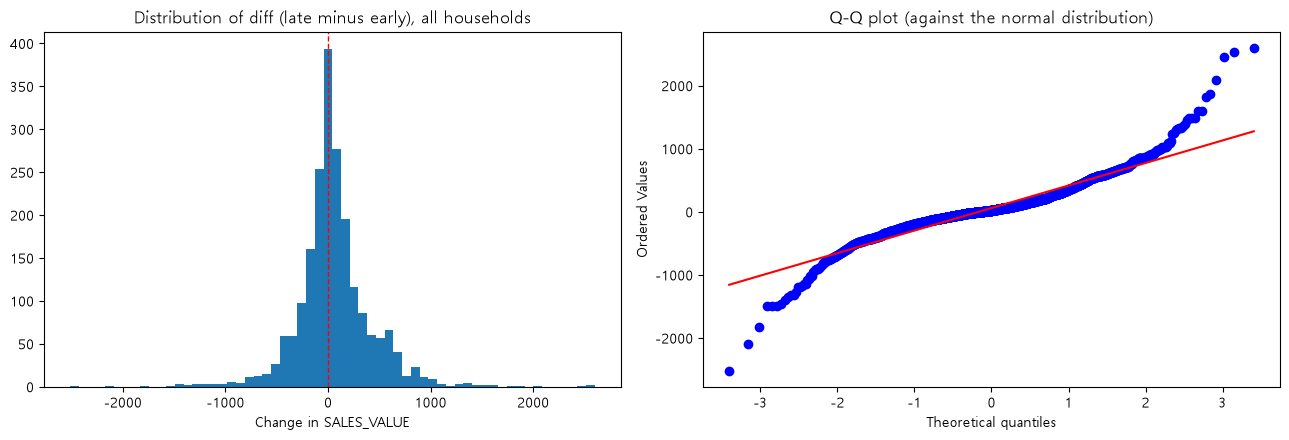

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(diff_all, bins=60)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_title("Distribution of diff (late minus early), all households")
axes[0].set_xlabel("Change in SALES_VALUE")

stats.probplot(diff_all, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot (against the normal distribution)")

plt.tight_layout()
plt.show()


## 4. [Comparison 2: independent] Normality and equal variances of diff by group (top 20% vs remaining 80%)

Before comparing diff (the increase) between the two groups, check normality within each group and equal variances between them.
- Normality: Shapiro-Wilk per group (small samples) / D'Agostino (large samples)
- Equal variances: Levene test (used first because it does not require normality)

In [7]:
top_diff  = panel.loc[panel["group"] == "top 20%", "diff"].values
rest_diff = panel.loc[panel["group"] == "remaining 80%", "diff"].values

print(f"Top 20% sample size: {len(top_diff)}, remaining 80% sample size: {len(rest_diff)}")

results = []
for name, arr in [("top 20%", top_diff), ("remaining 80%", rest_diff)]:
    if len(arr) < 5000:
        stat, p = stats.shapiro(arr)
        test_name = "Shapiro-Wilk"
    else:
        stat, p = stats.normaltest(arr)
        test_name = "D'Agostino-Pearson"
    results.append({"group": name, "test": test_name, "statistic": stat, "p_value": p,
                     "normality": "rejected (non-normal)" if p < 0.05 else "not rejected (normal)"})

normality_summary = pd.DataFrame(results)
normality_summary


Top 20% sample size: 419, remaining 80% sample size: 1676


,group,test,statistic,p_value,normality
0,top 20%,Shapiro-Wilk,0.985169,2.763608e-04,rejected (non-normal)
1,remaining 80%,Shapiro-Wilk,0.849854,3.382346e-37,rejected (non-normal)


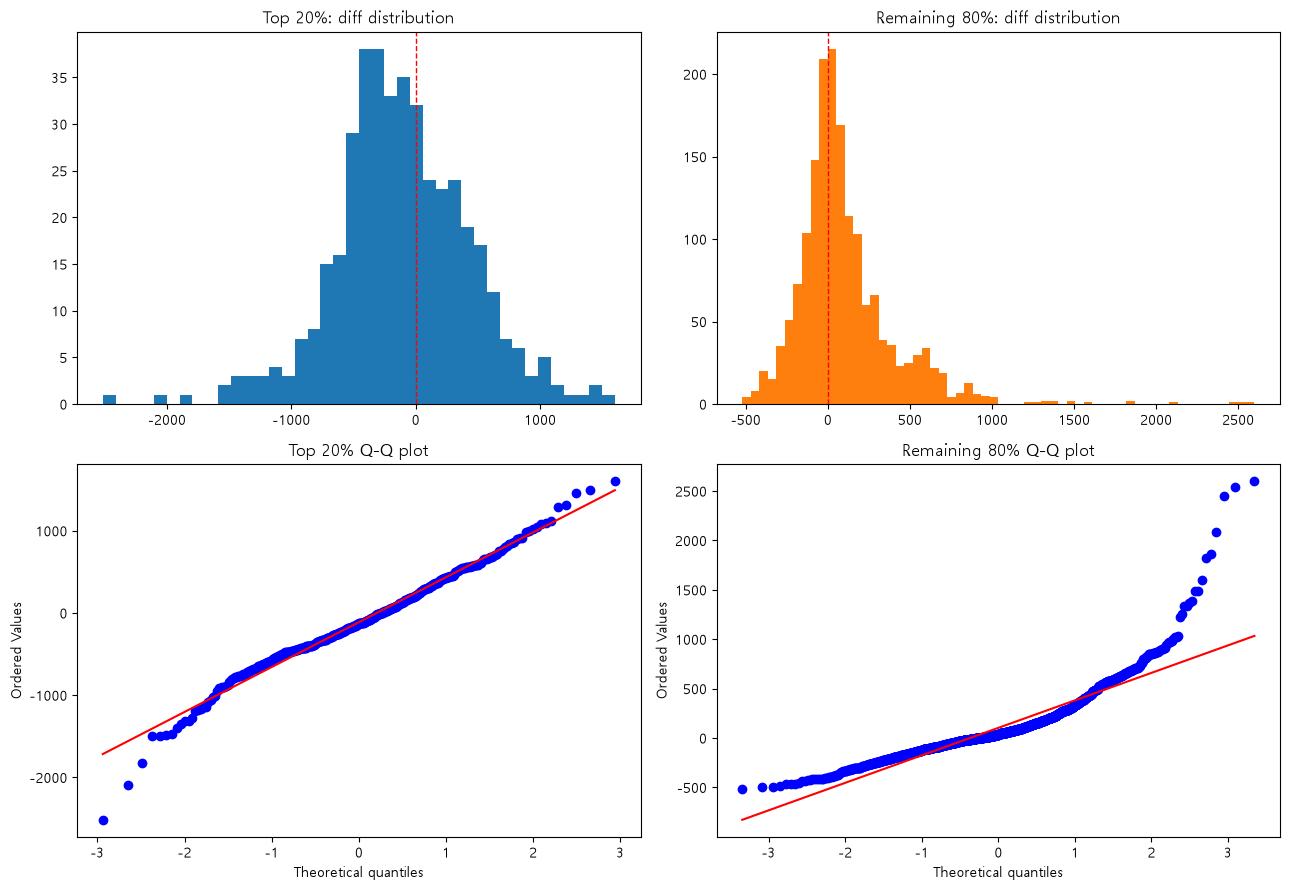

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0,0].hist(top_diff, bins=40, color='C0')
axes[0,0].axvline(0, color='red', linestyle='--', linewidth=1)
axes[0,0].set_title("Top 20%: diff distribution")

axes[0,1].hist(rest_diff, bins=60, color='C1')
axes[0,1].axvline(0, color='red', linestyle='--', linewidth=1)
axes[0,1].set_title("Remaining 80%: diff distribution")

stats.probplot(top_diff, dist="norm", plot=axes[1,0])
axes[1,0].set_title("Top 20% Q-Q plot")

stats.probplot(rest_diff, dist="norm", plot=axes[1,1])
axes[1,1].set_title("Remaining 80% Q-Q plot")

plt.tight_layout()
plt.show()


In [9]:
# Equal variances (Levene test: no normality assumption needed)
levene_stat, levene_p = stats.levene(top_diff, rest_diff)
print(f"Levene test: statistic={levene_stat:.4f}, p-value={levene_p:.6f}")
print("-> Equal variances " + ("rejected (variances differ, so Welch's t-test is needed)" if levene_p < 0.05 else "not rejected (equal variances can be assumed)"))

print(f"\nTop 20% variance: {np.var(top_diff, ddof=1):.2f}")
print(f"Remaining 80% variance: {np.var(rest_diff, ddof=1):.2f}")


Levene test: statistic=227.7537, p-value=0.000000
-> Equal variances rejected (variances differ, so Welch's t-test is needed)

Top 20% variance: 300682.58
Remaining 80% variance: 91072.58


## 5. Summary of the diagnostics: settle the tests to use in the next step

Based on the results above (whether normality was rejected, whether equal variances were rejected), tabulate automatically the method to use for the actual hypothesis tests in the next notebook.

In [10]:
diff_all_normal = p >= 0.05 if n < 5000 else p >= 0.05  # reuses p from the cell in section 3
top_normal = normality_summary.loc[normality_summary["group"]=="top 20%", "p_value"].values[0] >= 0.05
rest_normal = normality_summary.loc[normality_summary["group"]=="remaining 80%", "p_value"].values[0] >= 0.05
equal_var = levene_p >= 0.05

decision = pd.DataFrame([
    {
        "comparison": "1. all households, paired (late minus early)",
        "normality_met": diff_all_normal,
        "recommended_test": "paired t-test" if diff_all_normal else "Wilcoxon signed-rank test",
    },
    {
        "comparison": "2. top 20% vs remaining 80% (the increase, independent)",
        "normality_met": top_normal and rest_normal,
        "equal_variance_met": equal_var,
        "recommended_test": (
            "Student's t-test" if (top_normal and rest_normal and equal_var) else
            "Welch's t-test" if (top_normal and rest_normal and not equal_var) else
            "Mann-Whitney U"
        ),
    },
])
decision


,comparison,normality_met,recommended_test,equal_variance_met
0,"1. all households, paired (late minus early)",False,Wilcoxon signed-rank test,NaN
1,"2. top 20% vs remaining 80% (the increase, ind...",False,Mann-Whitney U,False


In [11]:
# --- source CSV: normality and variance tests
_sw = stats.shapiro(diff_all)
_rows = [{"sample": "diff_all_paired", "n": len(diff_all), "test": "Shapiro-Wilk",
          "statistic": _sw.statistic, "p_value": _sw.pvalue}]
for _, r in normality_summary.iterrows():
    _rows.append({"sample": {"top 20%": "top20", "remaining 80%": "rest80"}[r["group"]],
                  "n": len(top_diff) if r["group"] == "top 20%" else len(rest_diff),
                  "test": r["test"], "statistic": r["statistic"], "p_value": r["p_value"]})
pd.DataFrame(_rows).to_csv(OUT_DIR / "h4_normality_tests.csv", index=False)
pd.DataFrame([{
    "levene_statistic": levene_stat, "levene_p_value": levene_p,
    "var_top20": np.var(top_diff, ddof=1), "var_rest80": np.var(rest_diff, ddof=1),
    "var_ratio_top_over_rest": np.var(top_diff, ddof=1) / np.var(rest_diff, ddof=1),
}]).to_csv(OUT_DIR / "h4_levene.csv", index=False)

In [12]:
def compute_group_summary(early_n, top_x_pct=TOP_X_PCT):
    """Compute diff (late minus early) for the top X% vs the rest while varying the early-window length (early_n)"""
    early_w = tx_stable[
        (tx_stable["WEEK_NO"] >= STABLE_MIN_WEEK) &
        (tx_stable["WEEK_NO"] < STABLE_MIN_WEEK + early_n)
    ]
    late_w = tx_stable[
        (tx_stable["WEEK_NO"] > STABLE_MAX_WEEK - early_n) &
        (tx_stable["WEEK_NO"] <= STABLE_MAX_WEEK)
    ]

    s_early = early_w.groupby("household_key")["SALES_VALUE"].sum().rename("sales_early")
    s_late  = late_w.groupby("household_key")["SALES_VALUE"].sum().rename("sales_late")

    p = pd.concat([s_early, s_late], axis=1).dropna()
    p["diff"] = p["sales_late"] - p["sales_early"]

    cutoff = p["sales_early"].quantile(1 - top_x_pct/100)
    p["group"] = np.where(p["sales_early"] >= cutoff, "top X%", "rest")

    summary = p.groupby("group")["diff"].agg(["count", "mean", "median", "std"])
    summary["early_n"] = early_n
    return summary.reset_index(), p

results = []
panels = {}
for N in [8, 10, 12]:
    summary, p = compute_group_summary(N)
    results.append(summary)
    panels[N] = p

sensitivity_df = pd.concat(results, ignore_index=True)
sensitivity_df = sensitivity_df[["early_n", "group", "count", "mean", "median", "std"]]
sensitivity_df

,early_n,group,count,mean,median,std
0,8,rest,1611,92.420118,31.45,253.178658
1,8,top X%,403,-97.164640,-121.07,449.908931
2,10,rest,1676,102.743013,36.49,301.782339
3,10,top X%,419,-111.489618,-131.45,548.345308
4,12,rest,1731,117.846771,43.43,341.746020
5,12,top X%,433,-120.211824,-122.73,624.901074


In [13]:
# --- source CSV: sensitivity to the early-window length
# The saved CSV keeps its original Korean group labels (top X% / the rest), written here as unicode escapes.
_GROUP_LABEL_SAVED = {"top X%": "\uc0c1\uc704X%", "rest": "\ub098\uba38\uc9c0"}
sensitivity_df.assign(group_en=sensitivity_df["group"].map({"top X%": "top", "rest": "rest"}),
                      group=sensitivity_df["group"].map(_GROUP_LABEL_SAVED)) \
    .to_csv(OUT_DIR / "h4_sensitivity_window.csv", index=False)

In [14]:
# See at a glance whether the sign (direction) itself flips with N
pivot = sensitivity_df.pivot(index="early_n", columns="group", values="mean")
pivot["sign_match"] = (pivot["top X%"] > 0) == (pivot.get("rest", pivot.iloc[:,0]*0) ["rest"] if False else True)  # placeholder guard
pivot

group,rest,top X%,sign_match
early_n,,,
8,92.420118,-97.164640,False
10,102.743013,-111.489618,False
12,117.846771,-120.211824,False


In [15]:
# A clearer version: a separate table of the mean diff and its sign for top X% / rest by N
pivot = sensitivity_df.pivot(index="early_n", columns="group", values="mean")
pivot["top X%_sign"] = np.where(pivot["top X%"] > 0, "increase (+)", "decrease (-)")
pivot["rest_sign"] = np.where(pivot["rest"] > 0, "increase (+)", "decrease (-)")
pivot

group,rest,top X%,top X%_sign,rest_sign
early_n,,,,
8,92.420118,-97.164640,decrease (-),increase (+)
10,102.743013,-111.489618,decrease (-),increase (+)
12,117.846771,-120.211824,decrease (-),increase (+)


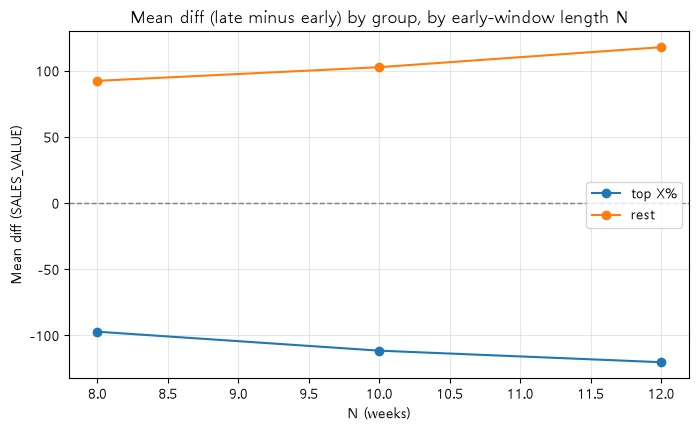

In [16]:
# Plot: change in the mean diff of the two groups with N
fig, ax = plt.subplots(figsize=(8, 4.5))
for group in ["top X%", "rest"]:
    sub = sensitivity_df[sensitivity_df["group"] == group]
    ax.plot(sub["early_n"], sub["mean"], marker='o', label=group)

ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_title("Mean diff (late minus early) by group, by early-window length N")
ax.set_xlabel("N (weeks)")
ax.set_ylabel("Mean diff (SALES_VALUE)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [17]:
# Also check how much the members of the top X% group themselves overlap across N (for the regression-to-the-mean diagnosis)
top_households_by_n = {N: set(panels[N][panels[N]["group"]=="top X%"].index) for N in [8,10,12]}

for n1, n2 in [(8,10), (10,12), (8,12)]:
    overlap = top_households_by_n[n1] & top_households_by_n[n2]
    union = top_households_by_n[n1] | top_households_by_n[n2]
    print(f"N={n1} vs N={n2}: {len(overlap)} overlapping households / {len(union)} in the union (Jaccard {len(overlap)/len(union):.2f})")

N=8 vs N=10: 371 overlapping households / 451 in the union (Jaccard 0.82)
N=10 vs N=12: 395 overlapping households / 457 in the union (Jaccard 0.86)
N=8 vs N=12: 362 overlapping households / 474 in the union (Jaccard 0.76)


In [18]:
# --- source CSV: overlap of the top-X% sets across N
_rows = []
for n1, n2 in [(8, 10), (10, 12), (8, 12)]:
    _ov = top_households_by_n[n1] & top_households_by_n[n2]
    _un = top_households_by_n[n1] | top_households_by_n[n2]
    _rows.append({"n_a": n1, "n_b": n2, "overlap": len(_ov), "union": len(_un), "jaccard": len(_ov) / len(_un)})
pd.DataFrame(_rows).to_csv(OUT_DIR / "h4_sensitivity_jaccard.csv", index=False)

## Next steps

- Run the actual hypothesis tests with the methods settled in the table above (p-value + effect size + confidence interval, including Bonferroni correction)
- The third comparison of H4-1 (the change in the sales share itself) will be handled separately by bootstrap
- Run the 8-week/12-week sensitivity checks by changing only the `EARLY_N` value in this notebook and re-running it the same way